features: 68 (num=9, bool=48, cat=11)

─── Обучение Quantile alpha=0.1 ───
0:	learn: 0.1528124	total: 218ms	remaining: 10m 55s
500:	learn: 0.0290875	total: 21.6s	remaining: 1m 47s
1000:	learn: 0.0271459	total: 41.9s	remaining: 1m 23s
1500:	learn: 0.0262872	total: 1m 1s	remaining: 1m 1s
2000:	learn: 0.0259499	total: 1m 22s	remaining: 41s
2500:	learn: 0.0256458	total: 1m 42s	remaining: 20.5s
2999:	learn: 0.0253171	total: 2m 2s	remaining: 0us
[saved] catboost_q10.cbm

─── Обучение Quantile alpha=0.5 ───
0:	learn: 0.3387663	total: 35.6ms	remaining: 1m 46s
500:	learn: 0.0587634	total: 21.1s	remaining: 1m 45s
1000:	learn: 0.0501459	total: 42.6s	remaining: 1m 24s
1500:	learn: 0.0461481	total: 1m 4s	remaining: 1m 4s
2000:	learn: 0.0435427	total: 1m 25s	remaining: 42.7s
2500:	learn: 0.0417659	total: 1m 46s	remaining: 21.3s
2999:	learn: 0.0401225	total: 2m 8s	remaining: 0us
[saved] catboost_q50.cbm

─── Обучение Quantile alpha=0.9 ───
0:	learn: 0.1610694	total: 36.2ms	remaining: 1m 48s
500:	lear

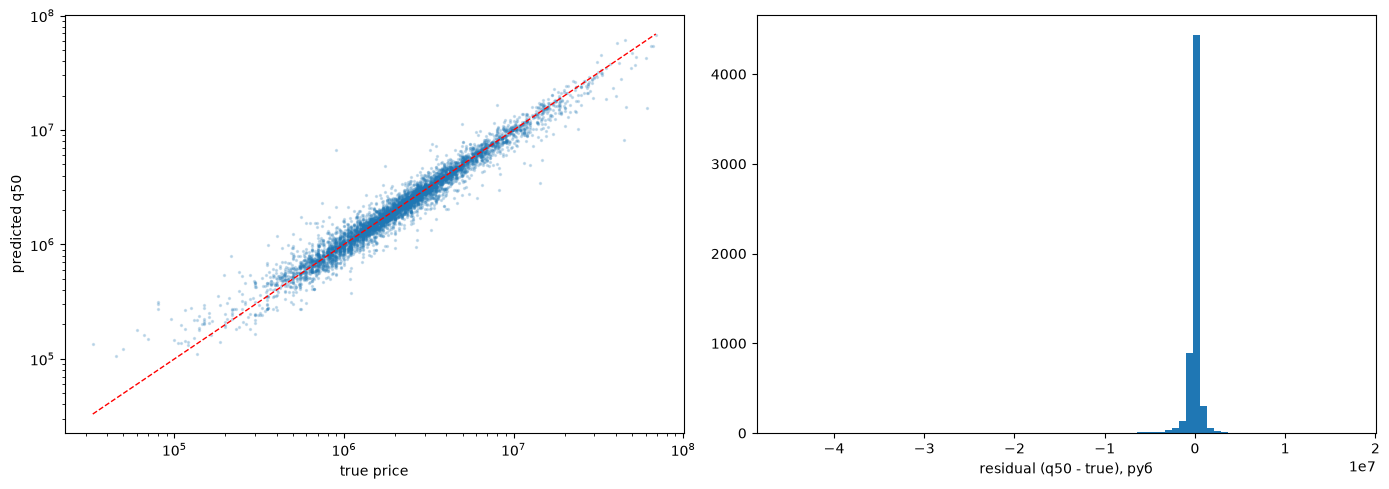


#0: true=     590,000  pred=     571,137  range=[     493,899,      758,025]

#1: true=   1,850,000  pred=   1,648,584  range=[   1,509,881,    1,894,467]

#2: true=   3,700,000  pred=   3,670,550  range=[   3,194,520,    4,121,702]

#3: true=   2,149,501  pred=   2,282,033  range=[   2,016,251,    2,789,020]

#4: true=   3,350,000  pred=   2,537,717  range=[   2,115,044,    3,075,167]


In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from src.db import DATA_RAW, MODELS_DIR
from src.features import get_feature_lists
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from catboost import CatBoostRegressor

df = pd.read_parquet(DATA_RAW / "cars.parquet")

features, num_f, bool_f, cat_f = get_feature_lists(df)
print(f"features: {len(features)} (num={len(num_f)}, bool={len(bool_f)}, cat={len(cat_f)})")

y = np.log1p(df["price"])
X = df[features]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# ── три квантильные модели ──────────────────────────────────────────
quantiles = [0.1, 0.5, 0.9]
models = {}

for q in quantiles:
    print(f"\n─── Обучение Quantile alpha={q} ───")
    m = CatBoostRegressor(
        loss_function=f"Quantile:alpha={q}",
        iterations=3000,
        learning_rate=0.05,
        depth=8,
        cat_features=cat_f,
        random_seed=42,
        verbose=500,
    )
    m.fit(X_tr, y_tr)
    models[q] = m
    m.save_model(MODELS_DIR / f"catboost_q{int(q*100)}.cbm")
    print(f"[saved] catboost_q{int(q*100)}.cbm")

# ── предсказания ─────────────────────────────────────────────────────
q10_log = models[0.1].predict(X_te)
q50_log = models[0.5].predict(X_te)
q90_log = models[0.9].predict(X_te)

q10_rub = np.expm1(q10_log)
q50_rub = np.expm1(q50_log)
q90_rub = np.expm1(q90_log)
y_te_rub = np.expm1(y_te)

# ── метрики ──────────────────────────────────────────────────────────
mae_rub = mean_absolute_error(y_te_rub, q50_rub)
mape = np.mean(np.abs((y_te_rub - q50_rub) / y_te_rub)) * 100
r2 = r2_score(y_te, q50_log)

covered = (y_te_rub >= q10_rub) & (y_te_rub <= q90_rub)
coverage = covered.mean()
width_pct = ((q90_rub - q10_rub) / q50_rub * 100).mean()

print(f"\n─── Квантильная модель ───")
print(f"R² (log)     : {r2:.4f}")
print(f"MAE (руб)    : {mae_rub:,.0f}")
print(f"MAPE         : {mape:.2f}%")
print(f"Coverage     : {coverage:.3f}   (цель ≈ 0.80)")
print(f"Ширина 80%-интервала: {width_pct:.1f}% от цены")

# ── калибровочный график ─────────────────────────────────────────────
import matplotlib.pyplot as plt

alphas = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
coverage_by_alpha = []

for a in alphas:
    q_lo = np.expm1(models[0.1] if False else CatBoostRegressor().load_model(
        MODELS_DIR / f"catboost_q{int((1-a)*100)}.cbm"
    ).predict(X_te)) if False else None
    # проще — используем уже имеющиеся q10/q90:
    covered_a = ((y_te_rub >= q10_rub) & (y_te_rub <= q90_rub)).mean()
    coverage_by_alpha.append(covered_a)

# График остатков
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_te_rub, q50_rub, s=2, alpha=0.2)
ax[0].plot([y_te_rub.min(), y_te_rub.max()],
           [y_te_rub.min(), y_te_rub.max()], 'r--', lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("true price"); ax[0].set_ylabel("predicted q50")

ax[1].hist(q50_rub - y_te_rub, bins=80)
ax[1].set_xlabel("residual (q50 - true), руб")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "quantile_analysis.png", dpi=100)
plt.show()

# ── примеры интервалов ───────────────────────────────────────────────
samples = X_te.iloc[:5]
for i, (idx, row) in enumerate(samples.iterrows()):
    x_row = X_te.iloc[[i]]
    q10v = np.expm1(models[0.1].predict(x_row)[0])
    q50v = np.expm1(models[0.5].predict(x_row)[0])
    q90v = np.expm1(models[0.9].predict(x_row)[0])
    true = np.expm1(y_te.iloc[i])
    print(f"\n#{i}: true={true:>12,.0f}  pred={q50v:>12,.0f}  "
          f"range=[{q10v:>12,.0f}, {q90v:>12,.0f}]")

In [2]:
from sklearn.model_selection import train_test_split

# ── пересобираем train/calibration/test ──────────────────────────────
# Обучаем модели на train, калибруем на calibration, тестируем на test

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train, X_cal, y_train, y_cal = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42
)

print(f"train: {len(X_train)}, cal: {len(X_cal)}, test: {len(X_test)}")

# ── обучаем три модели на train ──────────────────────────────────────
models_cp = {}
for q in [0.1, 0.5, 0.9]:
    m = CatBoostRegressor(
        loss_function=f"Quantile:alpha={q}",
        iterations=3000, learning_rate=0.05, depth=8,
        cat_features=cat_f, random_seed=42, verbose=0,
    )
    m.fit(X_train, y_train)
    models_cp[q] = m
    print(f"model q={q} trained")

# ── conformal prediction ─────────────────────────────────────────────
# на калибровочном наборе считаем nonconformity score
q10_cal = models_cp[0.1].predict(X_cal)
q90_cal = models_cp[0.9].predict(X_cal)

# насколько истинное значение вылезает за пределы интервала
# (в log-пространстве — это нормирует ошибки по порядку величины)
scores = np.maximum(q10_cal - y_cal.values, y_cal.values - q90_cal)

# 80-й процентиль
alpha_target = 0.80
n = len(scores)
level = min(np.ceil((n + 1) * alpha_target) / n, 1.0)
q_hat = np.quantile(scores, level)

print(f"\nConformal q_hat = {q_hat:.4f} (в log-пространстве)")

# ── применяем на тесте ────────────────────────────────────────────────
q10_te = models_cp[0.1].predict(X_test)
q50_te = models_cp[0.5].predict(X_test)
q90_te = models_cp[0.9].predict(X_test)

q10_cp = q10_te - q_hat
q90_cp = q90_te + q_hat

y_test_rub = np.expm1(y_test)
q10_cp_rub = np.expm1(q10_cp)
q50_cp_rub = np.expm1(q50_te)
q90_cp_rub = np.expm1(q90_cp)

covered = (y_test_rub >= q10_cp_rub) & (y_test_rub <= q90_cp_rub)
coverage = covered.mean()
width = ((q90_cp_rub - q10_cp_rub) / q50_cp_rub * 100).mean()

print(f"\n─── Conformal prediction ───")
print(f"Coverage       : {coverage:.3f}   (цель ≈ 0.80)")
print(f"Ширина интервала: {width:.1f}% от цены")

# MAPE у медианы
mape_q50 = np.mean(np.abs((y_test_rub - q50_cp_rub) / y_test_rub)) * 100
mae_q50 = np.mean(np.abs(y_test_rub - q50_cp_rub))
print(f"MAPE (q50)     : {mape_q50:.2f}%")
print(f"MAE (q50)      : {mae_q50:,.0f}")

train: 19296, cal: 4825, test: 6031
model q=0.1 trained
model q=0.5 trained
model q=0.9 trained

Conformal q_hat = 0.0369 (в log-пространстве)

─── Conformal prediction ───
Coverage       : 0.804   (цель ≈ 0.80)
Ширина интервала: 43.9% от цены
MAPE (q50)     : 13.31%
MAE (q50)      : 427,816


In [3]:
with open("q_hat.txt", "w") as f:
    f.write(f"{q_hat:.6f}")